# H1 (supporting): which features matter, and does the paper's own model work on them?

Two analyses that explain the H1 result rather than test a separate claim.

1. **Feature ranking.** Train an MLP on sign inputs and rank features by how often flipping each one changes its
   prediction. Then refit the paper's polynomial logistic regression on the top $k$ features, varying $k$ and the
   degree $d$. If this reaches 90%, the basis was wrong, not the universal approximation theorem.
2. **Noise ceiling.** The accuracy of the per-pattern Bernoulli MLE (a lookup table: for each sign pattern of the top
   $k$ features, predict the more common training label) estimates how much of the label is predictable at all.

Same protocol as H1: 5 seeds, stratified 60/20/20 split, $k$ and $d$ chosen on validation data, test split used once
per seed. Inputs are rounded to their signs; since $x_j^2 = 1$, the polynomial only needs products of distinct
features.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from include.config import NS, SEEDS, TARGET
from include.data import load, to_sign, split
from include.models import mlp, fit, accuracy
from include.features import flip_influence, fit_poly, fit_lookup, n_terms
from include.stats import chebyshev_eps, mean_std
from include.tracking import track, save_json
from include.figures import use_paper_style, savefig
from include.plots_h1 import plot_influence, plot_topk, plot_poly_degree

use_paper_style()
torch.set_num_threads(4)

KS = (2, 4, 6, 8, 10, 12)  # numbers of top features to try
DEGREES = (1, 2, 3, 4, 6, 8, 10, 12)  # polynomial degrees to try (only d <= k)
MAX_TERMS = 4096                      # skip (k, d) pairs with more polynomial terms than this


def score(predict, S, y):
    return float((predict(S) == y).mean())

## 1. Rank the features, then fit both models on the top $k$

In [2]:
res = {n: {"influence": [], "lookup": {}, "poly": {}} for n in NS}
with track("H1_features"):
    for n in NS:
        X, y = load(n)
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            S_tr, S_va, S_te = to_sign(X_tr), to_sign(X_va), to_sign(X_te)
            torch.manual_seed(seed)
            model, _ = fit(mlp(n, 256, 3), S_tr, y_tr, S_va, y_va, seed=seed)
            influence = flip_influence(model, S_tr)
            res[n]["influence"].append(influence.tolist())
            order = np.argsort(influence)[::-1]

            for k in KS:
                top = order[:k]
                r = res[n]["lookup"].setdefault(k, {"val": [], "test": []})
                predict = fit_lookup(S_tr, y_tr, top)
                r["val"].append(score(predict, S_va, y_va))
                r["test"].append(score(predict, S_te, y_te))
                for d in DEGREES:
                    if d > k or n_terms(k, d) > MAX_TERMS:
                        continue
                    r = res[n]["poly"].setdefault(f"{k},{d}", {"val": [], "test": []})
                    predict = fit_poly(S_tr, y_tr, top, d)
                    r["val"].append(score(predict, S_va, y_va))
                    r["test"].append(score(predict, S_te, y_te))
            print(f"n={n} seed={seed}: MLP test {accuracy(model, S_te, y_te):.3f}, top features {order[:12].tolist()}",
                  flush=True)
        res[n]["N_test"] = len(y_te)

n=20 seed=0: MLP test 0.923, top features [9, 4, 1, 12, 10, 7, 2, 5, 0, 15, 6, 3]


n=20 seed=1: MLP test 0.922, top features [9, 4, 1, 7, 12, 10, 2, 5, 0, 15, 17, 6]


n=20 seed=2: MLP test 0.924, top features [9, 4, 1, 10, 7, 12, 5, 2, 15, 0, 17, 19]


n=20 seed=3: MLP test 0.930, top features [9, 4, 1, 10, 12, 7, 2, 15, 5, 0, 14, 6]


n=20 seed=4: MLP test 0.924, top features [9, 4, 1, 12, 10, 7, 2, 5, 0, 15, 6, 16]


n=30 seed=0: MLP test 0.936, top features [10, 11, 28, 17, 5, 26, 2, 19, 14, 20, 6, 8]


... (6 outputs left out)

n=40 seed=2: MLP test 0.939, top features [6, 25, 30, 24, 15, 12, 7, 21, 36, 39, 10, 37]


n=40 seed=3: MLP test 0.944, top features [25, 6, 15, 30, 24, 12, 21, 7, 36, 39, 37, 17]


n=40 seed=4: MLP test 0.946, top features [25, 6, 30, 24, 12, 15, 21, 7, 36, 39, 16, 13]


[H1_features] 17572s, ~219.65 Wh, ~27.24 gCO2e


## 2. Choose $k$ (and $d$) on validation data, then check the test accuracy

$\varepsilon$ is the Chebyshev half-width for one model on one test split ($\delta = 0.05$).

In [3]:
summary = {}
for n in NS:
    eps = chebyshev_eps(res[n]["N_test"])
    best_poly = max(res[n]["poly"], key=lambda key: np.mean(res[n]["poly"][key]["val"]))
    best_k = max(res[n]["lookup"], key=lambda k: np.mean(res[n]["lookup"][k]["val"]))
    summary[n] = {"eps": eps}
    for name, key, r in (("poly", best_poly, res[n]["poly"][best_poly]), ("lookup", best_k, res[n]["lookup"][best_k])):
        mu, sd = mean_std(r["test"])
        summary[n][name] = {"choice": key, "val": float(np.mean(r["val"])), "mean": mu, "sd": sd,
                            "reaches_target": bool(mu - eps > TARGET)}
    p, l = summary[n]["poly"], summary[n]["lookup"]
    print(f"n={n}: eps {eps:.3f}")
    print(f"    poly LR, (k, d) = ({p['choice']}): test {p['mean']:.3f} +- {p['sd']:.3f}, minus eps > 0.90: {p['reaches_target']}")
    print(f"    lookup table (noise ceiling), k = {l['choice']}: test {l['mean']:.3f} +- {l['sd']:.3f}")

save_json({"results": {str(n): r for n, r in res.items()},
           "summary": {str(n): s for n, s in summary.items()}}, "H1_features.json")

n=20: eps 0.046
    poly LR, (k, d) = (10,8): test 0.957 +- 0.002, minus eps > 0.90: True
    lookup table (noise ceiling), k = 10: test 0.956 +- 0.002
n=30: eps 0.035
    poly LR, (k, d) = (10,8): test 0.961 +- 0.002, minus eps > 0.90: True
    lookup table (noise ceiling), k = 10: test 0.961 +- 0.002
n=40: eps 0.028
    poly LR, (k, d) = (10,6): test 0.960 +- 0.001, minus eps > 0.90: True
    lookup table (noise ceiling), k = 10: test 0.960 +- 0.001


## 3. Figures

How often flipping each feature changes the MLP's prediction (mean over seeds).

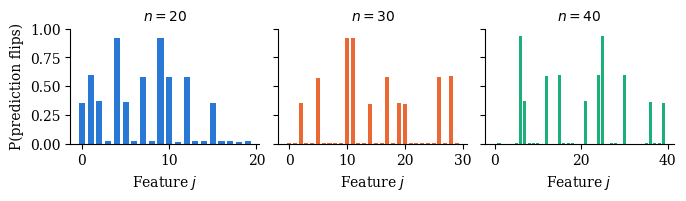

In [4]:
fig = plot_influence({n: np.mean(res[n]["influence"], axis=0) for n in NS})
savefig(fig, "H1_influence")
plt.show()

Test accuracy against the number of top features: the paper's polynomial LR with every product of the $k$
features ($d = k$), and the lookup table (dotted). The dashed line is the 90% target.

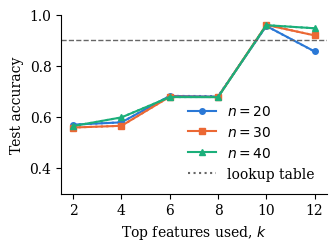

In [5]:
fig = plot_topk(res)
savefig(fig, "H1_topk")
plt.show()

Test accuracy of the paper's polynomial LR against its degree, on the $k$ chosen on validation data.

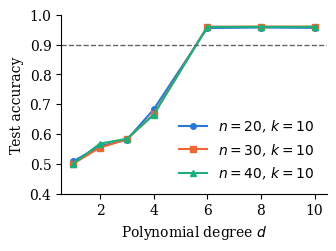

In [6]:
k_for = {n: int(summary[n]["poly"]["choice"].split(",")[0]) for n in NS}
fig = plot_poly_degree(res, k_for)
savefig(fig, "H1_poly_degree")
plt.show()